In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_absolute_error,mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

In [100]:
import os
os.getcwd()

'/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/notebook'

In [101]:
ratings=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/ratings.csv")
movies=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/movies.csv")
users=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/users.csv")

In [102]:
print(ratings.columns)
print(movies.columns)
print(users.columns)

Index(['user_id', 'movie_id', 'rating', 'timestamp'], dtype='object')
Index(['movie_id', 'title', 'genre'], dtype='object')
Index(['user_id', 'age', 'gender', 'occupation', 'zip_code'], dtype='object')


In [103]:
max_rating = ratings.rating.max()
min_rating = ratings.rating.min()
num_ratings = len(ratings)
num_users = ratings.user_id.nunique()
num_movies = ratings.movie_id.nunique()
print(f'The number of ratings : {num_ratings}')
print(f'The number of unique users : {num_users}')
print(f'The number of unique movies : {num_movies}')
# this rating part if written better or is okay??
print(f'The rating scale from min : {min_rating} to {max_rating}')

The number of ratings : 100000
The number of unique users : 943
The number of unique movies : 1682
The rating scale from min : 1 to 5


### What the profile numbers mean

| | Count of ratings | Mean of ratings |
|---|---|---|
| **Per user** | How active the user is | How generous the user is |
| **Per movie** | How popular the movie is, and how much evidence we have | How well liked the movie is |

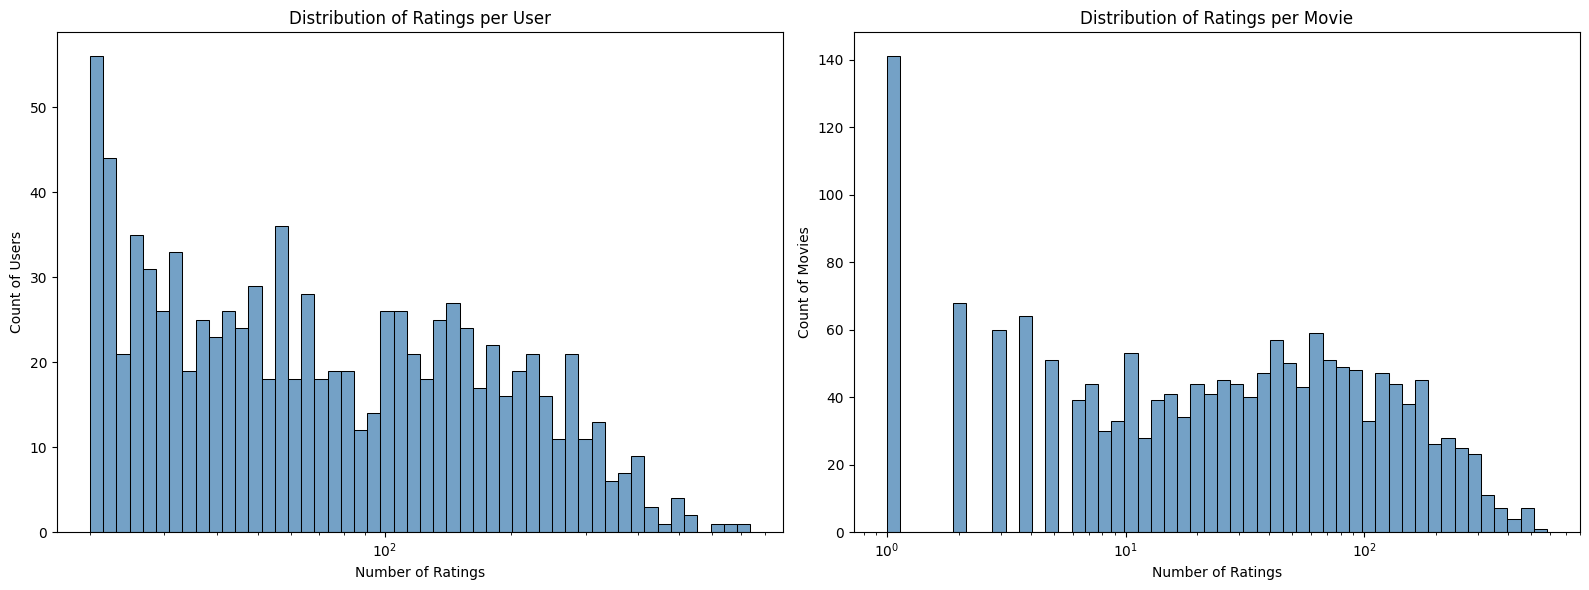

In [104]:
ratings_per_user = ratings.groupby('user_id')['rating'].count()
ratings_per_movie = ratings.groupby('movie_id')['rating'].count()
## for mean and median 
mean_rating_per_movie = ratings.groupby('movie_id')['rating'].mean()
median_rating_per_movie = ratings.groupby('movie_id')['rating'].median()

### better visually appealing graph design should be simple to code as well or its fine
# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(ratings_per_user, bins=50, ax=axes[0], color='steelblue',log_scale=True)
axes[0].set_title('Distribution of Ratings per User')
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Count of Users')

sns.histplot(ratings_per_movie, bins=50, ax=axes[1], color='steelblue',log_scale=True)
axes[1].set_title('Distribution of Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Count of Movies')

plt.tight_layout()
plt.show()

### Sparsity: how much of the picture do we actually see?

Picture a giant spreadsheet. Each row is a member and each column is a movie. A cell is
filled only if that member rated that movie.

- 943 members x 1,682 movies = about 1.59 million cells
- Only 100,000 are filled, which is **6.3%**
- The other **93.7% are unknown**

**Why a missing rating is not a zero:** the scale runs from 1 to 5, so 0 is not a valid
rating. A blank means "we do not know", not "the member disliked it". They may simply
not have seen the movie. Treating blanks as zeros would pull averages down and make
unrelated members look similar.

**What sparsity means for our methods:** to compare two members we need movies both
have rated. With only 6.3% of the grid filled, most pairs share very few movies, so
similarities are noisy and some predictions cannot be made at all. Those fall back to a
simple average. Predicting the blank 93.7% is exactly the product's job.

In [105]:

density = num_ratings / (num_users * num_movies)
print(f"Density: {density:.2%}")

Density: 6.30%


In [106]:
# Size check and splitting data into 80/20 then further  80 into 80/20
outer_train_df,test_df = train_test_split(ratings,test_size=0.2,random_state=42)
fitting_df,validation_df = train_test_split(outer_train_df,test_size=0.2,random_state=42)
print('Number of rows in outer_train',len(outer_train_df))
print('Number of rows in test_df',len(test_df))
print('Number of rows in fitting_df',len(fitting_df))
print('Number of rows in validation_df',len(validation_df))
print(len(test_df)+len(fitting_df)+len(validation_df))

Number of rows in outer_train 80000
Number of rows in test_df 20000
Number of rows in fitting_df 64000
Number of rows in validation_df 16000
100000


In [107]:
# Dropping unseen users and movies
## why we do so?
# my understanding because density is 6.30% and we will train basis that only as these are of main use rest we dont have any idea
known_users_fit = set(fitting_df['user_id'].unique())
known_movies_fit = set(fitting_df['movie_id'].unique())
## why we used set here?

validation_filtered_df = validation_df[
    validation_df['user_id'].isin(known_users_fit)&
    validation_df['movie_id'].isin(known_movies_fit)
].copy()


known_users_outer = set(outer_train_df['user_id'].unique())
known_movies_outer = set(outer_train_df['movie_id'].unique())

test_filtered_df = test_df[
    test_df['user_id'].isin(known_users_outer)&
    test_df['movie_id'].isin(known_movies_outer)
].copy()

fitting_matrix=fitting_df.pivot(index='user_id',columns='movie_id',values='rating')
fitting_matrix




movie_id,1,2,3,4,5,6,7,8,9,10,...,1666,1670,1671,1672,1673,1676,1678,1679,1680,1681
user_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,3.0,NaN,NaN,3.0,NaN,4.0,NaN,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
941,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [108]:
print(len(fitting_df), len(validation_df), len(test_df))        # 64000 16000 20000

print(f"validation rows: {len(validation_df)} -> {len(validation_filtered_df)} "
      f"(dropped {len(validation_df) - len(validation_filtered_df)})")   # 16000 -> 15964 (dropped 36)
print(f"test rows: {len(test_df)} -> {len(test_filtered_df)} "
      f"(dropped {len(test_df) - len(test_filtered_df)})")               # 20000 -> 19969 (dropped 31)

print("fitting matrix shape:", fitting_matrix.shape)                      # (943, 1620)
print(f"filled share: {fitting_matrix.notna().mean().mean():.2%}")        # 4.19%


64000 16000 20000
validation rows: 16000 -> 15964 (dropped 36)
test rows: 20000 -> 19969 (dropped 31)
fitting matrix shape: (943, 1620)
filled share: 4.19%


The PDF's Section B asks you to explain one difference between the two. The split we made is random: rows are picked at random, so the fitting set contains a mix of old and new ratings, and so does the test set.
- Random holdout: the model can learn from ratings made after the ones it predicts. That is looking into the future. It's easy and stable, but it can give flattering scores.
- Chronological evaluation: train on earlier ratings and test on later ones, using the timestamp column. This mimics real use, where today's recommendations only know the past. Scores are usually lower, and more honest for a streaming service.

In [109]:
# Baseline 1 - The global mean
# Baseline 2 - The movie mean

global_mean = fitting_df['rating'].mean()
movie_mean = fitting_df.groupby('movie_id')['rating'].mean()

pred_global = pd.Series(global_mean, index=validation_filtered_df.index)
pred_movies = validation_filtered_df['movie_id'].map(movie_mean).fillna(global_mean)

predictions = {
    "global mean": pred_global,
    "movie mean": pred_movies,
}

actual = validation_filtered_df['rating']

results = []
for name, pred in predictions.items():
    rmse = mean_squared_error(actual, pred) ** 0.5   # no trailing comma
    mae = mean_absolute_error(actual, pred)
    results.append({"model": name, "RMSE": rmse, "MAE": mae})

pd.DataFrame(results).round(2)

,model,RMSE,MAE
0,global mean,1.12,0.94
1,movie mean,1.03,0.82


# user-user cosine
- First neighborhood model

In [110]:
sim=cosine_similarity(fitting_matrix.fillna(0))
sim_df=pd.DataFrame(sim,index=fitting_matrix.index,columns=fitting_matrix.index)
sim_df

user_id,1,2,3,4,5,6,7,8,9,10,...,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.138407,0.035604,0.026291,0.182965,0.294131,0.254767,0.222603,0.057297,0.211485,...,0.259658,0.089711,0.177404,0.099462,0.098962,0.069899,0.197840,0.081112,0.075237,0.269947
2,0.138407,1.000000,0.100373,0.101333,0.089142,0.143868,0.087696,0.084454,0.186726,0.156987,...,0.150413,0.248554,0.289816,0.220538,0.210745,0.150782,0.257068,0.144505,0.152038,0.073916
3,0.035604,0.100373,1.000000,0.254532,0.000000,0.056063,0.029917,0.041961,0.071365,0.032307,...,0.025949,0.019918,0.126194,0.031388,0.076350,0.022034,0.101368,0.027614,0.099309,0.000000
4,0.026291,0.101333,0.254532,1.000000,0.014700,0.032702,0.064433,0.080103,0.076850,0.044731,...,0.016766,0.053623,0.107285,0.061456,0.031321,0.000000,0.154643,0.074342,0.026297,0.040121
5,0.182965,0.089142,0.000000,0.014700,1.000000,0.124816,0.256232,0.196027,0.050009,0.149581,...,0.278816,0.017447,0.061281,0.041658,0.046708,0.005147,0.205209,0.090706,0.105527,0.163176
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,0.069899,0.150782,0.022034,0.000000,0.005147,0.054494,0.063772,0.113259,0.075674,0.000000,...,0.035220,0.190090,0.162268,0.157341,0.302251,1.000000,0.064493,0.087845,0.027621,0.107234
940,0.197840,0.257068,0.101368,0.154643,0.205209,0.227152,0.254967,0.116616,0.118368,0.217645,...,0.269207,0.032389,0.132196,0.068673,0.061485,0.064493,1.000000,0.080826,0.156721,0.193005
941,0.081112,0.144505,0.027614,0.074342,0.090706,0.051221,0.031602,0.076040,0.000000,0.030667,...,0.051726,0.195217,0.157111,0.159267,0.152195,0.087845,0.080826,1.000000,0.086540,0.118476


In [111]:
# Cell: top 5 neighbors of the busiest user, plus sanity checks
user_id = fitting_matrix.notna().sum(axis=1).idxmax()   # user with most ratings
top5 = sim_df.loc[user_id].drop(user_id).nlargest(5)    # drop self, keep 5 most similar
print(top5)

print("diagonal is 1:", np.allclose(np.diag(sim), 1))
print("symmetric:    ", np.allclose(sim, sim.T))

user_id
846    0.356336
437    0.348554
222    0.337625
749    0.336617
301    0.334403
Name: 405, dtype: float64
diagonal is 1: True
symmetric:     True


In [112]:
# Overlap is the number of movies two users have both rated.
# Cosine similarity can't tell whether its score came from 1 shared movie or 100.
overlap = fitting_matrix.notna().astype(int)
#  overlap.T @ overlap would be the movie-movie version. We'll use that for item-item models later.
overlap_df = overlap@overlap.T
# (np.diag(overlap_df) == fitting_matrix.notna().sum(axis=1)).all()
np.array_equal(np.diag(overlap_df), fitting_matrix.notna().sum(axis=1))
overlap_df.loc[user_id,top5.index]

user_id
846    118
437     82
222     97
749     81
301     71
Name: 405, dtype: int64

In [113]:
# fitting_matrix.sub(fitting_matrix.mean(axis=1))
user_means = fitting_matrix.mean(axis = 1)
centered = fitting_matrix.sub(user_means,axis = 0)
centered.mean(axis = 1)
# np.allclose(centered.mean(axis=1),0)

user_id
1      1.722528e-16
2      1.869849e-16
3      7.970832e-17
4     -2.960595e-16
5      2.061843e-16
           ...     
939    2.960595e-16
940    1.044916e-16
941   -2.960595e-16
942    5.027425e-17
943    3.116416e-17
Length: 943, dtype: float64

In [149]:


user_id = 864
movie_id = 143

# 1. user's rows (name them, so later lines stay short)
sim_row     = sim_df.loc[user_id]
overlap_row = overlap_df.loc[user_id]

# 2. mask (you already have it; rewrite using sim_row / overlap_row)
mask=(sim_row.index!=user_id)&(fitting_matrix[movie_id].notna())&(sim_row>0)&(overlap_row>=3)

# 3. neighbors: similarities of users who pass, best 20
eligible  = sim_row[mask]           
neighbors = eligible.nlargest(20) 
print(len(eligible), len(neighbors))

# 4. neighbors' centered ratings for this movie
their_ratings = centered.loc[neighbors.index,movie_id]   
# 5. weighted adjustment
adjustment = (neighbors * their_ratings).sum() / neighbors.sum()

# 6. prediction
prediction = user_means.loc[user_id] + adjustment
prediction = np.clip(prediction, 1, 5)

# 7. compare with the real rating
actual = validation_filtered_df.loc[
    (validation_filtered_df["user_id"] == user_id)
    & (validation_filtered_df["movie_id"] == movie_id),
    "rating",
].iloc[0]
print(len(neighbors), prediction, actual)


140 20
20 3.9689298797223125 4
